# LEGO Inventory – Person 1: Preprocessing and Segmentation

This notebook covers image loading, preprocessing and segmentation of LEGO brick photographs.

## 1. Imports

We import the libraries used in this notebook and print their versions, so the results can be reproduced later.

In [11]:
import random
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Record the library versions used for this run.
print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)

OpenCV: 5.0.0
NumPy: 2.5.3


## 2. Select a random test image

The test photographs are in the `test_images` folder. We find the image files, then pick one at random. Each time this cell runs, a different photo can be chosen.

In [12]:
TEST_IMAGE_DIR = Path("test_images")
IMAGE_EXTENSIONS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}


def list_test_images(folder):
    """Return the image files in a folder, sorted by name."""
    files = [
        path for path in folder.iterdir()
        if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS
    ]
    # Sorting keeps the list in the same order on every run.
    return sorted(files)


image_files = list_test_images(TEST_IMAGE_DIR)

# Stop early with a clear message if the folder is empty or missing.
if not image_files:
    raise FileNotFoundError(f"No images found in {TEST_IMAGE_DIR.resolve()}")

# random.choice picks one file from the list.
selected_image_path = random.choice(image_files)

print(f"Found {len(image_files)} test image(s).")
print(f"Selected: {selected_image_path}")

Found 3 test image(s).
Selected: test_images\3_red_lego_pieces.png


## 3. Load and show the selected image

OpenCV loads images in BGR order, but Matplotlib expects RGB. We convert the colours before showing the photo, so the bricks look the right colour.

Image size (height, width, channels): (1157, 1600, 3)


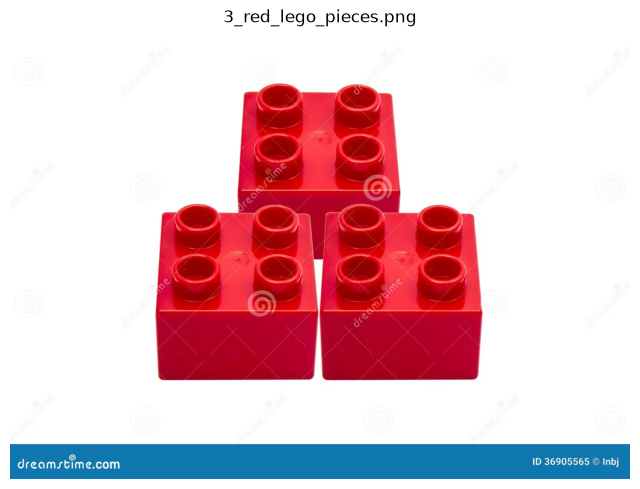

In [13]:
# IMREAD_COLOR returns 3 channels (BGR) and drops any transparency channel.
image_bgr = cv2.imread(str(selected_image_path), cv2.IMREAD_COLOR)

# imread returns None if the file cannot be read, so check for that.
if image_bgr is None:
    raise ValueError(f"Could not load image: {selected_image_path}")

image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

print(f"Image size (height, width, channels): {image_rgb.shape}")

plt.figure(figsize=(8, 6))
plt.imshow(image_rgb)
plt.title(selected_image_path.name)
plt.axis("off")
plt.show()

## 4. Grayscale and smoothing

A grayscale image keeps one brightness value per pixel. That is enough to separate bricks from a dark background, and it is the simplest starting point.

A light Gaussian blur smooths out stud texture and sensor noise. Without it, these details create false edges in the threshold step.

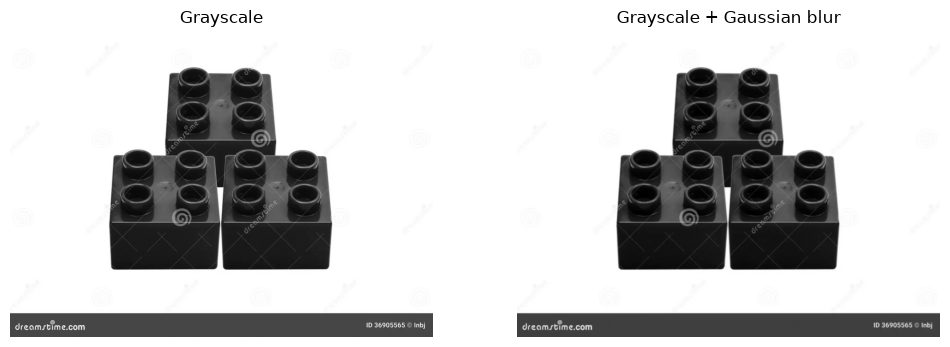

In [14]:
image_gray = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2GRAY)

# A 5x5 kernel is a small, common starting value for light smoothing.
image_blur = cv2.GaussianBlur(image_gray, (5, 5), 0)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(image_gray, cmap="gray")
axes[0].set_title("Grayscale")
axes[1].imshow(image_blur, cmap="gray")
axes[1].set_title("Grayscale + Gaussian blur")
for ax in axes:
    ax.axis("off")
plt.show()

## 5. Otsu threshold to make a binary mask

Otsu's method looks at the brightness histogram and picks the threshold that best splits it into two groups.

Which group is the bricks depends on the photo. A dark background needs the brighter pixels as bricks. A light background needs the darker pixels as bricks, so the threshold is inverted. We decide this from the outer border of the image, which is almost always background.

Otsu picks the threshold value automatically, so we do not need to tune it by hand for each photo.

Background is light: True
Otsu threshold value: 167


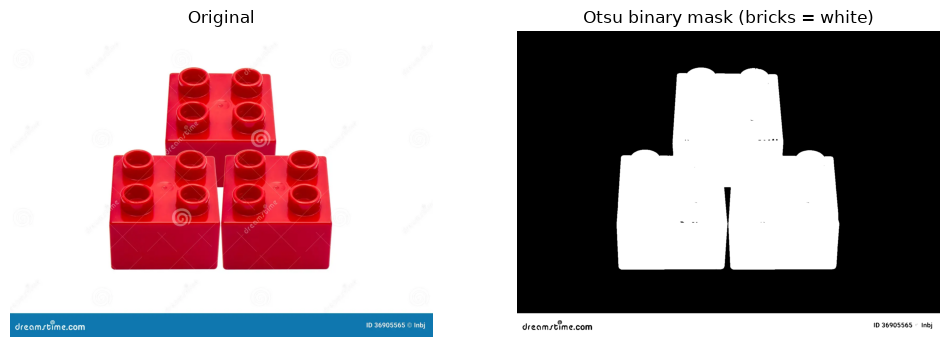

In [15]:
# The bricks can be darker or brighter than the background, so first check the
# background. The outer edge of the photo is almost always background, so we
# use its median brightness.
border_pixels = np.concatenate([
    image_blur[0, :], image_blur[-1, :], image_blur[:, 0], image_blur[:, -1]
])
background_is_light = np.median(border_pixels) > 127

# If the background is light, the bricks are the darker pixels, so we invert
# the threshold to make the bricks white (255).
if background_is_light:
    threshold_type = cv2.THRESH_BINARY_INV
else:
    threshold_type = cv2.THRESH_BINARY

# The threshold value passed in is ignored because THRESH_OTSU chooses it for us.
otsu_threshold, mask_otsu = cv2.threshold(
    image_blur, 0, 255, threshold_type + cv2.THRESH_OTSU
)

print(f"Background is light: {background_is_light}")
print(f"Otsu threshold value: {otsu_threshold:.0f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(image_rgb)
axes[0].set_title("Original")
axes[1].imshow(mask_otsu, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Otsu binary mask (bricks = white)")
for ax in axes:
    ax.axis("off")
plt.show()

## 6. Reference mask from the alpha channel

Some test images have a transparency (alpha) channel that marks where the bricks are. We can use it as a reference and measure how closely the Otsu mask agrees with it.

This only works if the alpha channel has transparent pixels. Some images have an alpha channel that is fully opaque, which gives no information, so we skip the check for those.

In [16]:
# Read the file again with IMREAD_UNCHANGED so the alpha channel is kept.
image_raw = cv2.imread(str(selected_image_path), cv2.IMREAD_UNCHANGED)

has_alpha = image_raw.ndim == 3 and image_raw.shape[2] == 4
# An alpha channel that is fully opaque (all 255) gives no reference, so we
# only use it when some pixels are transparent.
has_useful_alpha = has_alpha and np.any(image_raw[:, :, 3] < 255)

if has_useful_alpha:
    alpha = image_raw[:, :, 3]
    _, mask_alpha = cv2.threshold(alpha, 127, 255, cv2.THRESH_BINARY)

    # Agreement score: the share of pixels where both masks say the same thing.
    agreement = np.mean(mask_alpha == mask_otsu)
    print(f"Agreement with alpha mask: {agreement * 100:.2f}%")

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    axes[0].imshow(mask_alpha, cmap="gray", vmin=0, vmax=255)
    axes[0].set_title("Alpha reference mask")
    axes[1].imshow(mask_otsu, cmap="gray", vmin=0, vmax=255)
    axes[1].set_title("Otsu mask")
    for ax in axes:
        ax.axis("off")
    plt.show()
else:
    print("No useful alpha channel in this image, so there is no reference mask.")

No useful alpha channel in this image, so there is no reference mask.


## 7. Clean up the mask with morphology

Two small operations tidy the mask:
- **Opening** (erosion followed by dilation) removes small specks of noise outside the bricks.
- **Closing** (dilation followed by erosion) fills small holes inside the bricks, such as gaps caused by highlights.

We use an ellipse kernel because it suits the rounded corners of bricks.

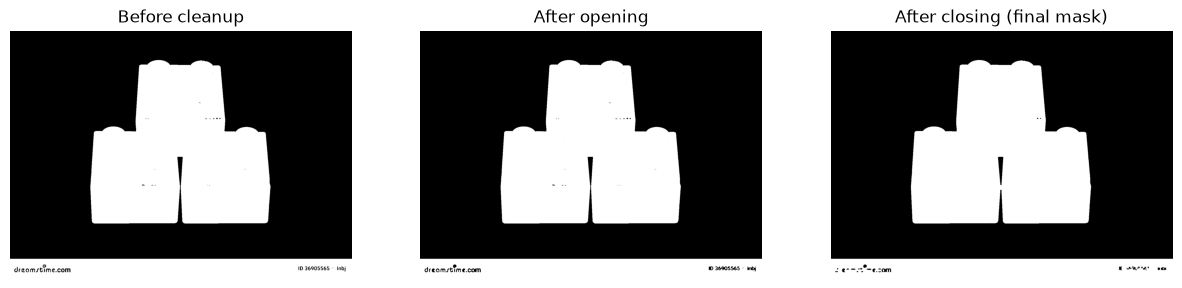

In [17]:
cleanup_kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))

mask_opened = cv2.morphologyEx(mask_otsu, cv2.MORPH_OPEN, cleanup_kernel)
mask_clean = cv2.morphologyEx(mask_opened, cv2.MORPH_CLOSE, cleanup_kernel)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(mask_otsu, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Before cleanup")
axes[1].imshow(mask_opened, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("After opening")
axes[2].imshow(mask_clean, cmap="gray", vmin=0, vmax=255)
axes[2].set_title("After closing (final mask)")
for ax in axes:
    ax.axis("off")
plt.show()